# Phase retrieval: Fienup's algorithms and phase diversity

Cameras record intensities. The phase of a field, which carries most of the
information about an object or about the aberrations of an optical system,
is lost. *Phase retrieval* recovers it from intensity measurements plus some
prior knowledge. This notebook treats two classic cases:

1. **Support-based phase retrieval** (coherent diffractive imaging). We
   measure only the far-field magnitude $|\mathcal{F}g|$ of an object $g$.
   We also know that $g$ is confined to a region, its *support*, and perhaps
   that it is real and nonnegative. Fienup's *error reduction* (ER) and
   *hybrid input-output* (HIO) algorithms find $g$ by alternating
   projections. *Shrink-wrap* finds the support along the way.
2. **Phase diversity** (pupil phase retrieval). We measure the PSF of an
   imaging system at a few known defocus values and recover the pupil phase,
   i.e. the aberrations. A multi-plane Gerchberg-Saxton iteration and a
   least squares fit of Zernike coefficients are compared.

`pyoptics.phase_retrieval` provides:

| Function | Purpose |
|---|---|
| `ER()`, `HIO()` | error reduction and hybrid input-output with support, reality and positivity constraints |
| `ShrinkWrap`, `autocorrelation_support()` | support update during the iteration, and the initial support from the autocorrelation |
| `fourier_error()`, `align()`, `twin()` | error metric, and removal of the trivial ambiguities (shift, constant phase, twin image) |
| `diversity_psfs()`, `defocus_to_waves()` | through-focus PSFs of a pupil, and defocus distance to a Fringe Z4 coefficient |
| `phase_diversity()` | pupil phase and Fringe Zernikes from through-focus PSFs (`method="fit"` or `"gs"`) |

All functions return a `RetrievalResult` with the error history per
iteration. The beam shaping counterpart, Gerchberg-Saxton for a phase-only
element, lives in `pyoptics.ifta` (notebook 07).

Conventions: $\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$; far-field
magnitudes are those of `fft.FT()`. Pupils are sampled on the frequency grid
of the PSF grid, as in `imaging`. Zernike coefficients are Fringe
Zernikes in waves, as in `litho`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyoptics import phase_retrieval as pr
from pyoptics.bases import FringeZernikes
from pyoptics.fft import FT
from pyoptics.imaging import pupil_coordinates
from pyoptics.processing import CameraNoiser, Scaler
from pyoptics.propagators import rayleigh_sommerfeld_I_TF
from pyoptics.imaging import get_psf
from pyoptics.utils import grid1d

plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower", "font.size": 11})


def show(ax, img, title, cmap="viridis", colorbar=True, **kwargs):
    im = ax.imshow(img, cmap=cmap, **kwargs)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
    if colorbar:
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    return im


def log_magnitude(F):
    return np.log10(np.abs(F)/np.abs(F).max() + 1e-6)

## 1. The phase problem and its trivial ambiguities

The test object is a real, nonnegative "transmission" image: a few bars and
disks of different brightness on a 128 × 128 grid, inside a 48 × 48 pixel
region. The grid is more than twice as large as the object, so the far
field is *oversampled*. This is the condition that makes the problem
uniquely solvable in 2D, up to the ambiguities discussed next.

Three operations leave $|\mathcal{F}g|$ unchanged:

- a shift (cyclic, by whole pixels, on a DFT grid),
- a constant phase factor $e^{i\alpha}$,
- the **twin image** $g^*(-x, -y)$.

No algorithm can tell these apart from the magnitude alone. `align()` undoes
them before we compare a reconstruction with the truth.

max. |F| difference, shifted: 1.1368683772161603e-13
max. |F| difference, twin:    5.684341886080802e-14


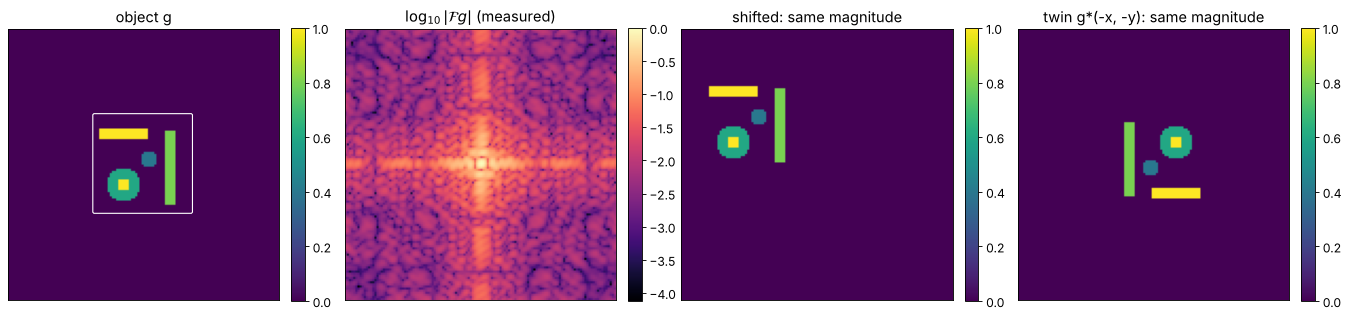

In [2]:
N = 128
n = np.arange(N) - N//2
X, Y = np.meshgrid(n, n)

obj = np.zeros((N, N))
obj[(np.abs(X + 10) < 12) & (np.abs(Y - 14) < 3)] = 1.0
obj[(np.abs(X - 12) < 3) & (np.abs(Y + 2) < 18)] = 0.8
obj[(X + 10)**2 + (Y + 10)**2 < 8**2] = 0.6
obj[(X + 10)**2 + (Y + 10)**2 < 3**2] = 1.0
obj[(X - 2)**2 + (Y - 2)**2 < 4**2] = 0.4
support = (np.abs(X + 1) < 24) & (np.abs(Y) < 24)   # a box around the object
magnitude = np.abs(FT(obj))

shifted = np.roll(obj, (20, -30), axis=(0, 1))
twinned = pr.twin(obj)
print("max. |F| difference, shifted:", np.max(np.abs(np.abs(FT(shifted)) - magnitude)))
print("max. |F| difference, twin:   ", np.max(np.abs(np.abs(FT(twinned)) - magnitude)))

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
show(axes[0], obj, "object g")
axes[0].contour(support, [0.5], colors="w", linewidths=1)
show(axes[1], log_magnitude(FT(obj)), r"$\log_{10}|\mathcal{F}g|$ (measured)", cmap="magma")
show(axes[2], shifted, "shifted: same magnitude")
show(axes[3], twinned, "twin g*(-x, -y): same magnitude")
plt.tight_layout()

## 2. Error reduction versus hybrid input-output

Both algorithms first apply the **Fourier projection**: keep the phase of
$\mathcal{F}g_k$ and impose the measured magnitude,
$g' = \mathcal{F}^{-1}[\,|F|\,e^{i\arg \mathcal{F}g_k}]$. Let $\gamma$ be
the set of pixels where $g'$ violates the object constraints (outside the
support, or negative if positivity is required). Then:

- **ER**: $g_{k+1} = g'$ off $\gamma$ and $0$ on $\gamma$, a projection
  onto the object constraints. Gerchberg-Saxton in disguise: the error
  $E_F = \lVert\,|\mathcal{F}g_k| - |F|\,\rVert / \lVert F\rVert$ never
  increases, but ER stagnates quickly.
- **HIO**: $g_{k+1} = g'$ off $\gamma$ and $g_k - \beta g'$ on $\gamma$.
  The negative feedback keeps pushing the iterate out of the local minima
  where ER gets stuck. Its $E_F$ jumps around, so HIO is usually finished
  with a few ER iterations.

Both start from the same random object inside the support.

ER, 600 iterations:            E_F = 1.41e-01, object error 6.49e-01
HIO 550 + ER 50 iterations:    E_F = 1.92e-07, object error 7.30e-07


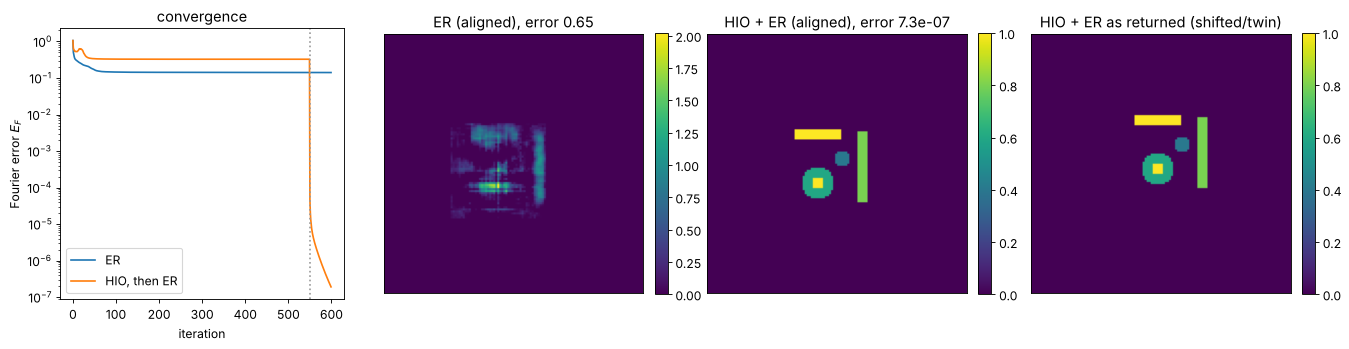

In [3]:
er = pr.ER(magnitude, support, N_iter=600, positivity=True, rng=1)
hio = pr.HIO(magnitude, support, beta=0.9, N_iter=550, positivity=True, rng=1)
hio_er = pr.ER(magnitude, support, N_iter=50, start=hio.obj, positivity=True)

er_aligned, er_err = pr.align(er.obj, obj)
hio_aligned, hio_err = pr.align(hio_er.obj, obj)
print(f"ER, 600 iterations:            E_F = {er.errors[-1]:.2e}, object error {er_err:.2e}")
print(f"HIO 550 + ER 50 iterations:    E_F = {hio_er.errors[-1]:.2e}, object error {hio_err:.2e}")

fig = plt.figure(figsize=(17, 4.5))
ax = fig.add_subplot(1, 4, 1)
ax.semilogy(er.errors, label="ER")
ax.semilogy(np.r_[hio.errors, hio_er.errors], label="HIO, then ER")
ax.axvline(550, color="0.6", ls=":")
ax.set_xlabel("iteration"); ax.set_ylabel("Fourier error $E_F$"); ax.legend(); ax.set_title("convergence")
show(fig.add_subplot(1, 4, 2), er_aligned.real, f"ER (aligned), error {er_err:.2f}")
show(fig.add_subplot(1, 4, 3), hio_aligned.real, f"HIO + ER (aligned), error {hio_err:.1e}")
show(fig.add_subplot(1, 4, 4), hio_er.obj, "HIO + ER as returned (shifted/twin)")
plt.tight_layout()

ER is stuck after a few dozen iterations, with a blurred, ghosted image.
HIO wanders for a while and then locks onto the solution. The final ER
iterations bring $E_F$ down to round-off. The raw output (right) is a
shifted copy or the twin image of the object, depending on the random start.

### How much prior knowledge is needed?

Here are HIO + ER runs from five random starts each, with different
constraints.

tight box, positivity                  object errors: 1.2e-05, 7.3e-07, 1.6e-05, 1.6e-05, 2.1e-06


tight box, real                        object errors: 7.3e-01, 4.5e-01, 8.3e-01, 7.3e-01, 6.6e-01


tight box, complex                     object errors: 6.5e-01, 8.9e-01, 7.8e-01, 9.4e-01, 7.1e-01


loose box, positivity                  object errors: 2.2e-05, 6.4e-01, 1.3e-05, 5.7e-05, 1.5e-05


autocorrelation support, positivity    object errors: 6.2e-06, 9.2e-06, 2.5e-05, 6.7e-06, 3.3e-05


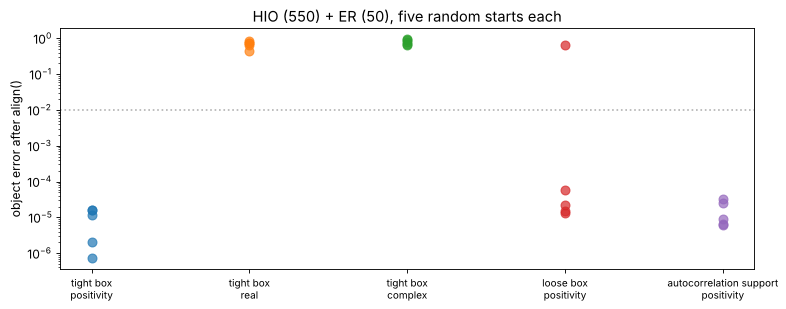

In [4]:
loose = (np.abs(X + 1) < 40) & (np.abs(Y) < 40)
cases = {
    "tight box, positivity": dict(support=support, positivity=True),
    "tight box, real": dict(support=support, real=True),
    "tight box, complex": dict(support=support),
    "loose box, positivity": dict(support=loose, positivity=True),
    "autocorrelation support, positivity": dict(support=pr.autocorrelation_support(magnitude), positivity=True),
}

results = {}
for name, kw in cases.items():
    errs = []
    for seed in range(5):
        r = pr.HIO(magnitude, N_iter=550, rng=seed, **kw)
        kw_er = {key: val for key, val in kw.items() if key != "support"}
        r = pr.ER(magnitude, kw["support"], N_iter=50, start=r.obj, **kw_er)
        errs.append(pr.align(r.obj, obj)[1])
    results[name] = errs
    print(f"{name:38s} object errors: " + ", ".join(f"{e:.1e}" for e in errs))

fig, ax = plt.subplots(figsize=(10, 4))
for i, (name, errs) in enumerate(results.items()):
    ax.semilogy([i]*len(errs), errs, "o", ms=8, alpha=0.7)
ax.set_xticks(range(len(results))); ax.set_xticklabels([s.replace(", ", "\n") for s in results], fontsize=9)
ax.set_ylabel("object error after align()"); ax.axhline(1e-2, color="0.7", ls=":")
ax.set_title("HIO (550) + ER (50), five random starts each")
plt.tight_layout()

Positivity is the strongest constraint. With it, even the loose
autocorrelation support works. Without it, the centrosymmetric box fails
in every run. A support that is symmetric under $\mathbf{x} 	o -\mathbf{x}$
cannot tell the object from its twin, so the iteration stagnates in a
superposition of both (Fienup and Wackerman, JOSA A 3, 1897 (1986)). Tight,
asymmetric supports help. Shrink-wrap finds such a support on its own.

## 3. Unknown support: shrink-wrap

Usually the support is not known. Its autocorrelation is: the inverse FT of
$|F|^2$ is the autocorrelation of $g$, which is twice as wide as $g$.
`autocorrelation_support()` thresholds it, which gives a safe but loose
start. **Shrink-wrap** (Marchesini et al. 2003) tightens it during the
iteration. Every 20 iterations, the modulus of the current estimate is
blurred by a Gaussian and thresholded at 20 % of its maximum to give the new
support. The blur shrinks from 3 to 1 pixel as the reconstruction sharpens.

Now the object is complex: the same amplitude with a smooth phase of up to
±0.8 rad, so neither positivity nor reality can help. Complex objects are
much harder. HIO can stagnate in a mixture of the object and its twin. The
usual remedy is to run a few random starts and keep the one with the
lowest Fourier error, which needs no knowledge of the true object. A
`callback` records snapshots of the support.

start 0: E_F = 1.9e-10, object error (needs the truth) 1.1e-09


start 1: E_F = 3.6e-02, object error (needs the truth) 8.5e-02


start 2: E_F = 4.1e-02, object error (needs the truth) 1.0e-01
best start 0: object error 1.1e-09; support pixels 668 (object: 528)


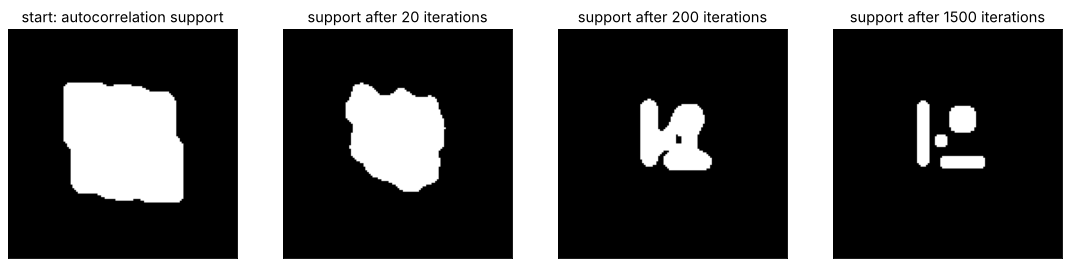

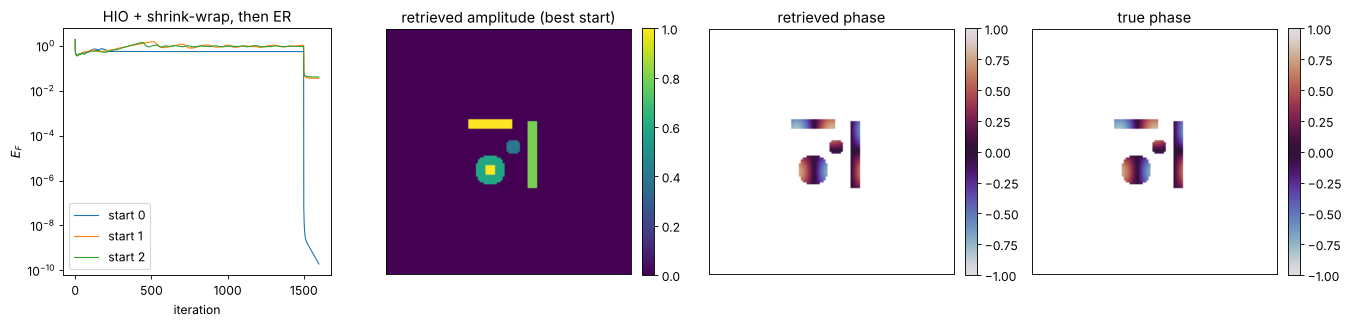

In [5]:
phase_obj = 0.8*np.cos(X/6.0)*np.sin(Y/7.0)
cobj = obj*np.exp(1j*phase_obj)
cmagnitude = np.abs(FT(cobj))

runs = []
for seed in range(3):
    snapshots = {}
    record = lambda i, g, s, snapshots=snapshots: snapshots.update({i: s.copy()}) if i in (20, 200, 1500) else None
    r = pr.HIO(cmagnitude, None, N_iter=1500, shrinkwrap=pr.ShrinkWrap(every=20, sigma=3.0, sigma_min=1.0, decay=0.95, threshold=0.2),
               rng=seed, callback=record)
    final = pr.ER(cmagnitude, r.support, N_iter=100, start=r.obj)
    runs.append((final.errors[-1], seed, r, final, snapshots))
    print(f"start {seed}: E_F = {final.errors[-1]:.1e}, object error (needs the truth) {pr.align(final.obj, cobj)[1]:.1e}")

E_F, seed, r, final, snapshots = min(runs, key=lambda run: run[0])
aligned, err = pr.align(final.obj, cobj)
print(f"best start {seed}: object error {err:.1e}; support pixels {r.support.sum()} (object: {(obj > 0).sum()})")

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
show(axes[0], pr.autocorrelation_support(cmagnitude), "start: autocorrelation support", cmap="gray", colorbar=False)
for ax, i in zip(axes[1:], sorted(snapshots)):
    show(ax, snapshots[i], f"support after {i} iterations", cmap="gray", colorbar=False)

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for E, s_, r_, f_, _ in runs:
    axes[0].semilogy(np.r_[r_.errors, f_.errors], lw=1, label=f"start {s_}")
axes[0].set_xlabel("iteration"); axes[0].set_ylabel("$E_F$"); axes[0].legend(); axes[0].set_title("HIO + shrink-wrap, then ER")
lit = np.abs(cobj) > 0.05
show(axes[1], np.abs(aligned), "retrieved amplitude (best start)")
show(axes[2], np.where(np.abs(aligned) > 0.05, np.angle(aligned), np.nan), "retrieved phase", cmap="twilight", vmin=-1, vmax=1)
show(axes[3], np.where(lit, np.angle(cobj), np.nan), "true phase", cmap="twilight", vmin=-1, vmax=1)
plt.tight_layout()

## 4. Noise

A real diffraction pattern is a photon count. We scale $|F|^2$ to a given
total photon number, add Poisson noise with `processing.CameraNoiser`, and
retrieve from the square root of the counts. With the default ER/HIO there is
no noise model. The reconstruction error decreases roughly like
$N_\mathrm{ph}^{-1/2}$.

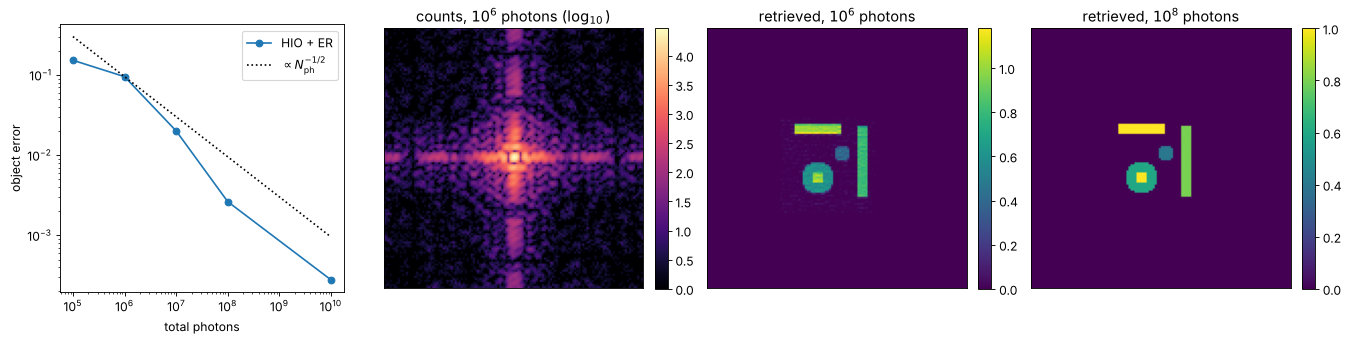

In [6]:
noiser = CameraNoiser("poisson", rng=7)
photons = [1e5, 1e6, 1e7, 1e8, 1e10]
noise_errors, examples = [], {}
for N_ph in photons:
    I = Scaler(N_ph, measure="total")(magnitude**2)
    counts = noiser(I)
    r = pr.HIO(np.sqrt(counts), support, N_iter=550, positivity=True, rng=1)
    r = pr.ER(np.sqrt(counts), support, N_iter=50, start=r.obj, positivity=True)
    rec = r.obj*np.sqrt(np.sum(magnitude**2)/np.sum(counts))   # back to the scale of obj
    aligned, err = pr.align(rec, obj)
    noise_errors.append(err)
    examples[N_ph] = (counts, aligned.real)

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
axes[0].loglog(photons, noise_errors, "o-", label="HIO + ER")
axes[0].loglog(photons, noise_errors[1]*np.sqrt(photons[1]/np.array(photons)), "k:", label=r"$\propto N_\mathrm{ph}^{-1/2}$")
axes[0].set_xlabel("total photons"); axes[0].set_ylabel("object error"); axes[0].legend()
show(axes[1], np.log10(examples[1e6][0] + 1), r"counts, $10^6$ photons ($\log_{10}$)", cmap="magma")
show(axes[2], examples[1e6][1], r"retrieved, $10^6$ photons")
show(axes[3], examples[1e8][1], r"retrieved, $10^8$ photons")
plt.tight_layout()

## 5. Pupil phase from through-focus PSFs: phase diversity

Now consider an imaging system with numerical aperture NA and an unknown
pupil phase $\varphi(P_x, P_y)$. The amplitude PSF is the inverse FT of the
pupil function $P = |P|\,e^{i\varphi}$, exactly as in `imaging.get_psf()`.
The pupil *amplitude* is known (a clear circle here). A single in-focus PSF
is not enough: $\varphi(\mathbf{P})$ and $-\varphi(-\mathbf{P})$ give the
same intensity, so the sign of all *even* aberrations (defocus, astigmatism,
spherical) is undetermined.

The remedy is **phase diversity**. We also record PSFs with a known extra
defocus, which adds $2\pi c_4 Z_4$ with the Fringe Zernike
$Z_4 = 2P^2 - 1$ to the pupil phase. `defocus_to_waves()` converts an axial
shift $\Delta z$ of the observation plane into $c_4$. Paraxially,
$k_z \approx k - k\,\mathrm{NA}^2 P^2/2$, so
$c_4 = -k\,\Delta z\,\mathrm{NA}^2/(8\pi)$. This is checked here against an
angular spectrum propagation of an aberrated PSF.

dz = -100 um -> c4 = +0.500 waves; max. deviation from propagation: 1.6e-03 of the peak
dz = +100 um -> c4 = -0.500 waves; max. deviation from propagation: 1.6e-03 of the peak


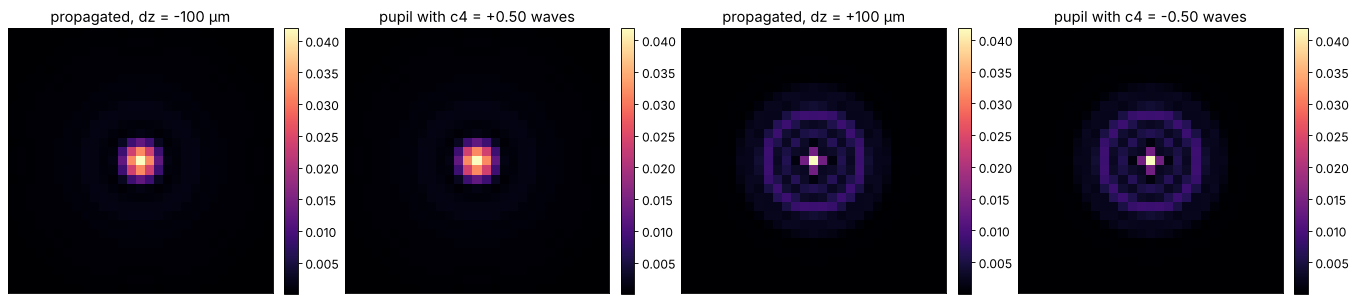

In [7]:
wl = 0.5                    # um
k = 2*np.pi/wl
NA = 0.1
N_chk = 256
L_chk = N_chk*wl/(4*NA)
x_chk = grid1d(-L_chk/2, L_chk/2, N_chk)
spherical = lambda P_x, P_y: 2*np.pi*0.3*(6*(P_x**2 + P_y**2)**2 - 6*(P_x**2 + P_y**2) + 1)   # 0.3 waves Z9
psf_focus = get_psf(x_chk, x_chk, NA, k, phase=spherical)

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
crop = slice(N_chk//2 - 14, N_chk//2 + 15)
for i, dz in enumerate((-100.0, 100.0)):
    I_prop = np.abs(rayleigh_sommerfeld_I_TF(psf_focus, x_chk, x_chk, dz, wl)[0])**2
    I_prop /= I_prop.sum()
    c4 = pr.defocus_to_waves(dz, NA, k)
    I_model = pr.diversity_psfs(x_chk, x_chk, NA, k, [c4], phase=spherical)[0]
    print(f"dz = {dz:+.0f} um -> c4 = {c4:+.3f} waves; max. deviation from propagation: "
          f"{np.max(np.abs(I_prop - I_model))/I_prop.max():.1e} of the peak")
    show(axes[2*i], I_prop[crop, crop], f"propagated, dz = {dz:+.0f} µm", cmap="magma")
    show(axes[2*i + 1], I_model[crop, crop], f"pupil with c4 = {c4:+.2f} waves", cmap="magma")
plt.tight_layout()

The small residual is the non-paraxial part of $k_z$. Note how different the
two sides of focus look with spherical aberration. This asymmetry is what
phase diversity exploits.

### The test system

NA = 0.25, λ = 0.5 µm, a 128 × 128 PSF grid with $\Delta x = \lambda/(4\,\mathrm{NA})$
(Nyquist for the intensity). The pupil radius is then 32 pixels. The
unknown pupil phase is a random combination of Fringe Zernikes 2 to 15 with
about 0.15 waves rms. Three PSFs are recorded at $c_4 = -0.75, 0, +0.75$
waves.

true pupil phase: 0.156 waves rms


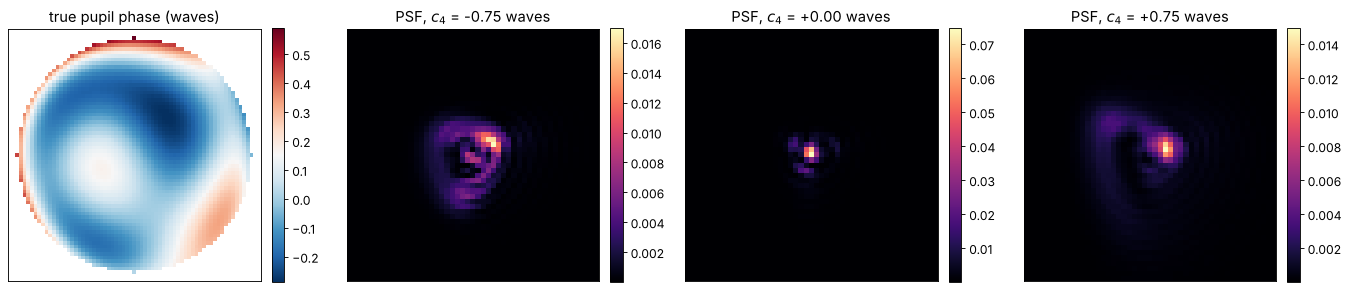

In [8]:
NA = 0.25
N_psf = 128
L = N_psf*wl/(4*NA)
x = grid1d(-L/2, L/2, N_psf)
P_x, P_y = pupil_coordinates(x, x, NA, k)
inside = P_x**2 + P_y**2 <= 1
zern = FringeZernikes(P_x[0], P_y[:, 0])
Z = lambda j: zern.eval_single_scattered(P_x, P_y, j)
pupil_crop = slice(N_psf//2 - 34, N_psf//2 + 35)
psf_crop = slice(N_psf//2 - 24, N_psf//2 + 25)


def phase_from(coeffs):
    return 2*np.pi*sum(c*Z(j) for j, c in coeffs.items())*inside


def rms_waves(phase, reference):
    d = (phase - reference)[inside]
    d -= d.mean()
    return np.sqrt(np.mean(d**2))/(2*np.pi)


rng = np.random.default_rng(0)
true = {j: rng.normal(0, 0.4)/np.sqrt(j) for j in range(2, 16)}
true_phase = phase_from(true)
print(f"true pupil phase: {rms_waves(true_phase, 0*true_phase):.3f} waves rms")

defocus = [-0.75, 0.0, 0.75]
psfs = pr.diversity_psfs(x, x, NA, k, defocus, phase=true_phase)

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
show(axes[0], np.where(inside, true_phase/(2*np.pi), np.nan)[pupil_crop, pupil_crop], "true pupil phase (waves)", cmap="RdBu_r")
for ax, d, p in zip(axes[1:], defocus, psfs):
    show(ax, p[psf_crop, psf_crop], f"PSF, $c_4$ = {d:+.2f} waves", cmap="magma")
plt.tight_layout()

### Why one in-focus PSF is not enough

Replace $\varphi(\mathbf{P})$ with $-\varphi(-\mathbf{P})$, i.e. flip the
sign of the even Zernikes and keep the odd ones. The amplitude PSF becomes
its complex conjugate, $h \to h^*$, so the in-focus intensity does not
change at all. Defocus is even, so the defocused PSFs swap sides of focus:
the PSF at $+c_4$ becomes the PSF at $-c_4$. A fit to the in-focus PSF alone
has no way to choose, and here it lands exactly on the wrong one.

in-focus PSFs equal: True
defocused PSFs swapped: True


fit to the in-focus PSF alone: residual phase error 0.204 waves rms, vs. the flipped solution 0.000 waves rms


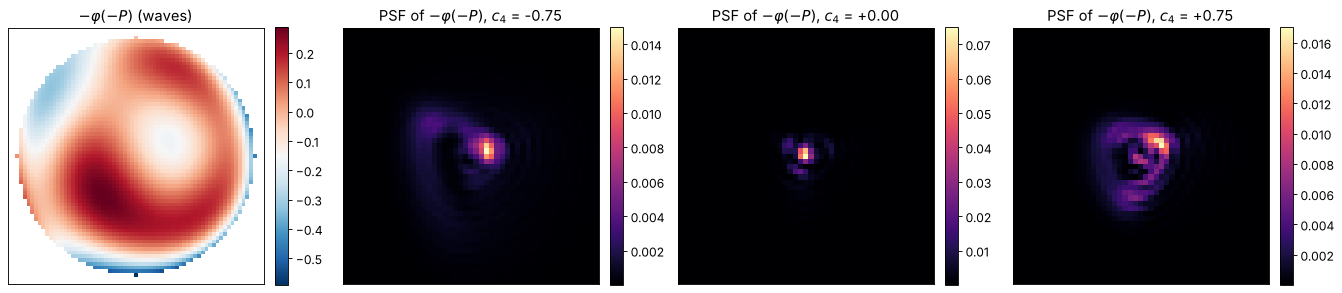

In [9]:
flipped = -true_phase[::-1, ::-1]
flipped = np.roll(flipped, (1, 1), axis=(0, 1))*inside     # -phi(-P) on the centred grid
psf_flip = pr.diversity_psfs(x, x, NA, k, defocus, phase=flipped)
print("in-focus PSFs equal:", np.allclose(psfs[1], psf_flip[1]))
print("defocused PSFs swapped:", np.allclose(psfs[0], psf_flip[2]) and np.allclose(psfs[2], psf_flip[0]))

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
show(axes[0], np.where(inside, flipped/(2*np.pi), np.nan)[pupil_crop, pupil_crop], r"$-\varphi(-P)$ (waves)", cmap="RdBu_r")
for ax, d, p in zip(axes[1:], defocus, psf_flip):
    show(ax, p[psf_crop, psf_crop], f"PSF of $-\\varphi(-P)$, $c_4$ = {d:+.2f}", cmap="magma")
plt.tight_layout()

single = pr.phase_diversity(psfs[1:2], [0.0], x, x, NA, k, n_zernike=15)
print(f"fit to the in-focus PSF alone: residual phase error {rms_waves(single.phase, true_phase):.3f} waves rms, "
      f"vs. the flipped solution {rms_waves(single.phase, flipped):.3f} waves rms")

### Retrieval: Zernike fit versus multi-plane Gerchberg-Saxton

- `method="fit"` models the three intensities with Fringe Zernikes 2 to 15
  and minimises the squared intensity residuals with
  `scipy.optimize.least_squares`, using the analytic Jacobian. The energy of
  the model PSF does not depend on the phase (Parseval), so each measured
  PSF is simply normalised to it. No scale factors need fitting.
- `method="gs"` (Misell's multi-plane Gerchberg-Saxton) cycles through the
  planes. In each, it propagates the current pupil to the PSF, imposes the
  measured modulus, propagates back and removes the known defocus, then
  imposes the known pupil amplitude. It needs no basis. Afterwards its phase
  is unwrapped (`unwrap.unwrap_quality_guided()`) and fitted with Zernikes.

The error is the normalised rms deviation of the model amplitudes
$\sqrt{I}$ from the measured ones.

fit: 3.8e-17 waves rms error, 7 evaluations, 1.21 s
gs:  3.6e-17 waves rms error, 300 iterations, 1.86 s


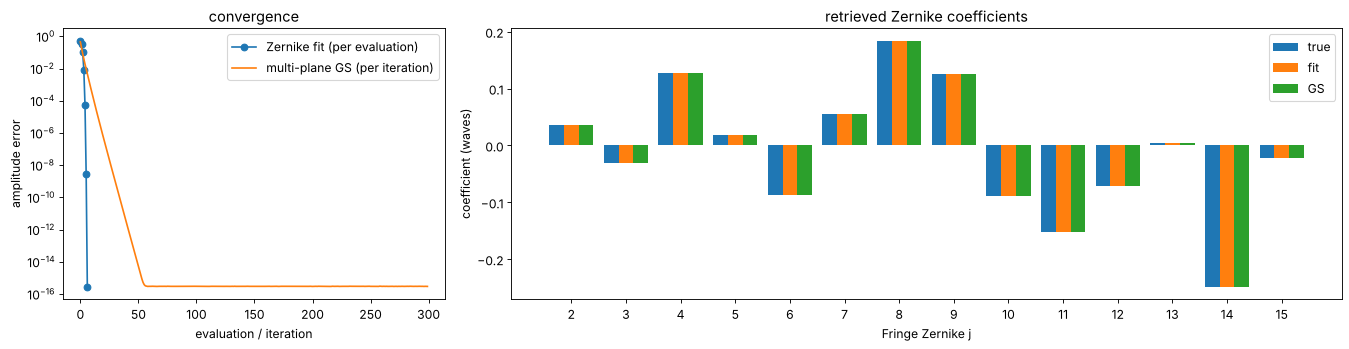

In [10]:
import time

t0 = time.perf_counter()
fit = pr.phase_diversity(psfs, defocus, x, x, NA, k, n_zernike=15, method="fit")
t_fit = time.perf_counter() - t0
t0 = time.perf_counter()
gs = pr.phase_diversity(psfs, defocus, x, x, NA, k, n_zernike=15, method="gs", N_iter=300)
t_gs = time.perf_counter() - t0
print(f"fit: {rms_waves(fit.phase, true_phase):.1e} waves rms error, {len(fit.errors)} evaluations, {t_fit:.2f} s")
print(f"gs:  {rms_waves(gs.phase, true_phase):.1e} waves rms error, {len(gs.errors)} iterations, {t_gs:.2f} s")

fig = plt.figure(figsize=(17, 4.5))
ax = fig.add_subplot(1, 3, 1)
ax.semilogy(fit.errors, "o-", label="Zernike fit (per evaluation)")
ax.semilogy(gs.errors, label="multi-plane GS (per iteration)")
ax.set_xlabel("evaluation / iteration"); ax.set_ylabel("amplitude error"); ax.legend(); ax.set_title("convergence")

ax = fig.add_subplot(1, 3, (2, 3))
j = np.arange(2, 16)
ax.bar(j - 0.27, [true[i] for i in j], 0.27, label="true")
ax.bar(j, [fit.zernikes[i] for i in j], 0.27, label="fit")
ax.bar(j + 0.27, [gs.zernikes[i] for i in j], 0.27, label="GS")
ax.set_xticks(j); ax.set_xlabel("Fringe Zernike j"); ax.set_ylabel("coefficient (waves)"); ax.legend()
ax.set_title("retrieved Zernike coefficients")
plt.tight_layout()

Without noise, both recover the phase to round-off. The fit needs fewer
than ten evaluations, but each one includes the Jacobian (one FFT per plane
and Zernike). GS needs about 50 cheap iterations here (two FFTs per plane).
Its convergence slows down for larger aberrations, the familiar behaviour of
alternating projections. The fit starts from zero and still converged for random
aberrations up to about half a wave rms in our trials. GS needs no basis, so
it can also capture phase structure beyond the Zernikes in use, such as a
segment step or a zone error. Its result can then be passed as `start` to a
fit.

## 6. Noise and the amount of diversity

Next, Poisson noise with `CameraNoiser`. Each PSF is scaled to a given peak
photon count per pixel. As expected, the error falls like
$N_\mathrm{ph}^{-1/2}$. The fit is better than GS because it uses the known
phase structure (14 parameters instead of about 3200 pupil pixels). Fitting
Zernikes to the GS phase recovers much of that advantage: the noise in the
pupil pixels is mostly of high spatial frequency and averages out in the
Zernike projection.

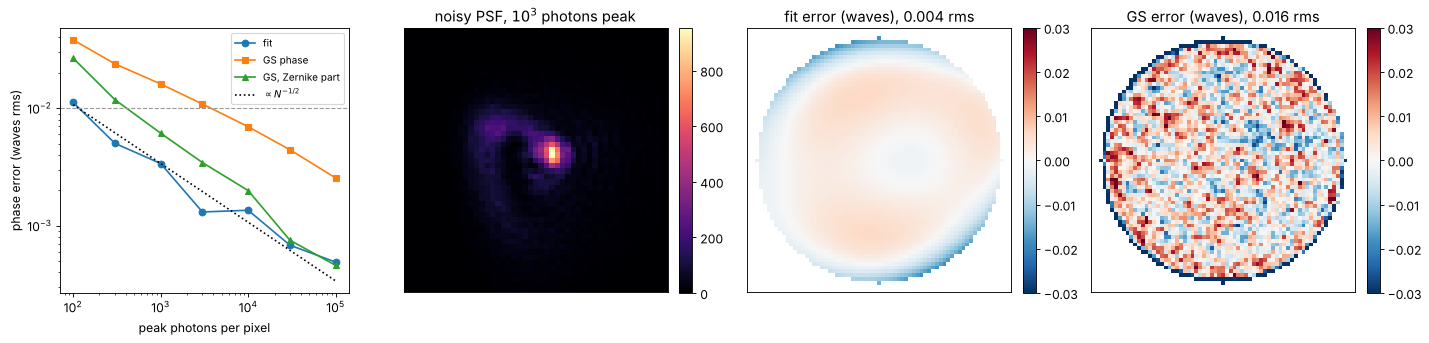

In [11]:
noiser = CameraNoiser("poisson", rng=11)
peaks = [1e2, 3e2, 1e3, 3e3, 1e4, 3e4, 1e5]
err_fit, err_gs, err_gs_z = [], [], []
for peak in peaks:
    noisy = np.array([noiser(Scaler(peak)(p)) for p in psfs])
    f = pr.phase_diversity(noisy, defocus, x, x, NA, k, n_zernike=15, method="fit")
    g = pr.phase_diversity(noisy, defocus, x, x, NA, k, n_zernike=15, method="gs", N_iter=100)
    err_fit.append(rms_waves(f.phase, true_phase))
    err_gs.append(rms_waves(g.phase, true_phase))
    err_gs_z.append(rms_waves(phase_from(g.zernikes), true_phase))

noisy_1e3 = np.array([noiser(Scaler(1e3)(p)) for p in psfs])
f_1e3 = pr.phase_diversity(noisy_1e3, defocus, x, x, NA, k, n_zernike=15, method="fit")
g_1e3 = pr.phase_diversity(noisy_1e3, defocus, x, x, NA, k, n_zernike=15, method="gs", N_iter=100)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
axes[0].loglog(peaks, err_fit, "o-", label="fit")
axes[0].loglog(peaks, err_gs, "s-", label="GS phase")
axes[0].loglog(peaks, err_gs_z, "^-", label="GS, Zernike part")
axes[0].loglog(peaks, err_fit[2]*np.sqrt(peaks[2]/np.array(peaks)), "k:", label=r"$\propto N^{-1/2}$")
axes[0].axhline(0.01, color="0.6", ls="--", lw=1)
axes[0].set_xlabel("peak photons per pixel"); axes[0].set_ylabel("phase error (waves rms)"); axes[0].legend(fontsize=9)
show(axes[1], noisy_1e3[2][psf_crop, psf_crop], "noisy PSF, $10^3$ photons peak", cmap="magma")
lim = 0.03
show(axes[2], np.where(inside, (f_1e3.phase - true_phase)/(2*np.pi), np.nan)[pupil_crop, pupil_crop],
     f"fit error (waves), {rms_waves(f_1e3.phase, true_phase):.3f} rms", cmap="RdBu_r", vmin=-lim, vmax=lim)
d_gs = (g_1e3.phase - true_phase)
d_gs -= d_gs[inside].mean()
show(axes[3], np.where(inside, d_gs/(2*np.pi), np.nan)[pupil_crop, pupil_crop],
     f"GS error (waves), {rms_waves(g_1e3.phase, true_phase):.3f} rms", cmap="RdBu_r", vmin=-lim, vmax=lim)
plt.tight_layout()

How much defocus should the diversity planes have? Too little, and the
planes carry nearly the same information as the focus. Too much, and the
light spreads over many pixels, which lowers the signal per pixel at a fixed
peak count. A sweep with $\pm c_4$ around focus at $10^3$ photons peak (each
point averaged over three noise realisations):

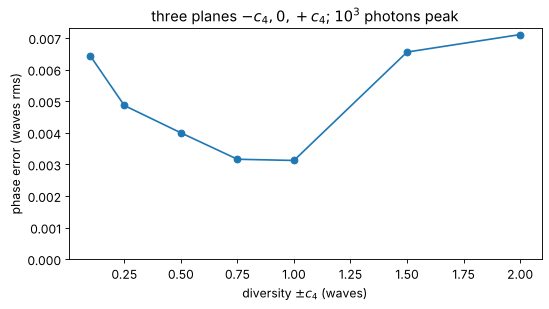

In [12]:
amounts = [0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0]
mean_err = []
for a in amounts:
    planes = [-a, 0.0, a]
    clean = pr.diversity_psfs(x, x, NA, k, planes, phase=true_phase)
    errs = []
    for rep in range(3):
        noisy = np.array([noiser(Scaler(1e3)(p)) for p in clean])
        errs.append(rms_waves(pr.phase_diversity(noisy, planes, x, x, NA, k, n_zernike=15).phase, true_phase))
    mean_err.append(np.mean(errs))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(amounts, mean_err, "o-")
ax.set_xlabel(r"diversity $\pm c_4$ (waves)"); ax.set_ylabel("phase error (waves rms)")
ax.set_title(r"three planes $-c_4, 0, +c_4$; $10^3$ photons peak")
ax.set_ylim(0, None)
plt.tight_layout()

A diversity of about half a wave to one wave of $c_4$ is best here. That
is one to two waves of peak-to-valley defocus, or
$\Delta z = 4\lambda c_4/\mathrm{NA}^2 \approx 2$ to $4\,\lambda/\mathrm{NA}^2$
(`defocus_to_waves()` converts). Larger values still work, at a gradually
higher error. In practice the
diversity defocus itself is known only to the accuracy of the focus stage.
A natural extension is to include it as a fit parameter.

## Summary

- `ER()` and `HIO()` retrieve an object from its Fourier magnitude. HIO
  escapes the stagnation of ER, and a few ER iterations polish the result.
  Tight supports and positivity make the problem much better conditioned.
  `ShrinkWrap` finds the support when only the autocorrelation is known.
- The result is unique only up to a shift, a constant phase and the twin
  image. `align()` removes these for comparisons.
- A single in-focus PSF cannot fix the sign of the even aberrations. Known
  defocus diversity resolves it, and `phase_diversity()` then recovers the
  pupil phase to below λ/100 rms without noise. `method="fit"` is fast and
  noise robust for Zernike-type aberrations. `method="gs"` is basis free
  and can seed the fit.